#### FFW SG2 - InteractiveMarker wrist IK test (with table)

Same as `sim_eef_controller_sg2_teleop.ipynb`, but `xml/table.xml` is merged into the scene so
the wrists are dragged around the table the real robot stands at.

Drag the two gizmos (one per wrist) to move the left/right arm targets. Each arm runs its own
small DLS IK solve toward its gizmo's pose. Shift-click a gizmo to switch it to rotate mode.

Note the IK here is **not** collision-aware: the solver will happily pull a wrist through the
tabletop. The table is in the scene for visual context and for collision *reporting* only.

In [1]:
%run ../package/init_project.py

import numpy as np

from ri_motion_v5_package.init_scripts.init_ipython_setup import *
from ri_motion_v5_package.init_scripts.init_qt import *
from ri_motion_v5_package.mujoco_sim import *
from ri_motion_v5_package.kinematics import *
from ri_motion_v5_package.utility import *
from ri_motion_v5_package.qt import *
from utils import *

app = get_qt_app()


[ffw_sg2_vr_teleoperation] initialized.
 - PROJECT_DIR: /Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation
Basic packages initialized.
 import numpy as np
 import matplotlib.pyplot as plt
 import scipy as sp
 from PIL import Image
[ipython] settings (retina, inline, qt) initialized.
[numpy] settings initialized.
[matplotlib] settings initialized.
[qt] package initialized.


In [2]:
xml_path = merge_mjcfs(
    included_mjcf_files = [
        str(FLOOR_XML_PATH),
        str(SG2_XML_PATH),
        str(SG2_PROJECT_XML_DIR / "table.xml"),  # <-- Add table MJCF here
    ],
    output_xml_path = str(SG2_SCENE_XML_PATH),)
env = MuJoCoParser(rel_xml_path=xml_path,verbose=False)
env.reset()
env.set_p("base_link","body",(0.0,0.0,0.01))

# Bend the elbows into a natural pose so both wrists start away from IK singularities.
env.forward(
    q           = [np.deg2rad(-90.0),np.deg2rad(-90.0)],
    joint_names = ["arm_l_joint4","arm_r_joint4"],)

command_joint_names = filter_existing_joint_names(env,SG2_REAL_COMMAND_JOINT_NAMES)
print("command joints (%d):"%len(command_joint_names),command_joint_names)

[merge_mjcfs] Merging [3] MJCF files:
  - [0] [/Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/floor_simple_white.xml]
  - [1] [/Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/ffw_sg2.xml]
  - [2] [/Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/table.xml]
[merge_mjcfs] Saved merged XML to:[/Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/scene_ffw_sg2_metaquest3.xml]
MuJoCo model loaded from [/Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/scene_ffw_sg2_metaquest3.xml].
command joints (17): ['lift_joint', 'head_joint1', 'head_joint2', 'arm_l_joint1', 'arm_l_joint2', 'arm_l_joint3', 'arm_l_joint4', 'arm_l_joint5', 'arm_l_joint6', 'arm_l_joint7', 'arm_r_joint1', 'arm_r_joint2', 'arm_r_joint3', 'arm_r_joint4', 'arm_r_joint5', 'arm_r_joint6', 'arm_r_joint7']


In [3]:
# One small (non-collision-aware) DLS IK solver per arm, each restricted to that arm's joints.
ik_solvers,arm_joint_names = create_sg2_arm_ik_solvers(
    env                = env,
    mujoco_parser_cls  = MuJoCoParser,
    body_ik_solver_cls = BodyPositionIKSolverRevPriBase,)
for hand_type in SG2_HAND_TYPES:
    print("%s arm IK joints (%d):"%(hand_type,len(arm_joint_names[hand_type])),arm_joint_names[hand_type])

MuJoCo model loaded from [/Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/scene_ffw_sg2_metaquest3.xml].
MuJoCo model loaded from [/Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/scene_ffw_sg2_metaquest3.xml].
left arm IK joints (7): ['arm_l_joint1', 'arm_l_joint2', 'arm_l_joint3', 'arm_l_joint4', 'arm_l_joint5', 'arm_l_joint6', 'arm_l_joint7']
right arm IK joints (7): ['arm_r_joint1', 'arm_r_joint2', 'arm_r_joint3', 'arm_r_joint4', 'arm_r_joint5', 'arm_r_joint6', 'arm_r_joint7']


In [4]:
env.init_viewer(title="SG2 InteractiveMarker Wrist IK Test (Table)",x_offset=0.24,y_offset=0.00,width=0.76,height=1.0,fontscale=180)
env.viewer.set_cam_info(180.0,2.8,-20.0,[0.0,0.0,0.95])
env.viewer.set_transparency(transparent=True)

# One draggable gizmo per wrist, seeded at that wrist's current pose.
markers = {
    hand_type: InteractiveMarker(
        env          = env,
        T            = get_sg2_wrist_control_T(env,hand_type),
        axis_len     = 0.12,
        ring_r       = 0.12,
        control_mode = "pR",)
    for hand_type in SG2_HAND_TYPES
}

[Marker IK Render] Initialized with [30.0]HZ. MAX_SEC:[inf]sec.
[Marker IK Render] Start ([30.0]HZ. MAX_SEC:[inf]sec).
[Marker IK Render][1] run delayed! T:[33.3]ms run:[420.4]ms]
[Marker IK Render][2][0.4s] delayed! T:[33.3]ms interval:[427.6]ms prev_run:[420.4]ms.
[Marker IK Render][2] run delayed! T:[33.3]ms run:[386.3]ms]
[Marker IK Render][3][0.8s] delayed! T:[33.3]ms interval:[388.5]ms prev_run:[386.3]ms.
[Marker IK Render][3] run delayed! T:[33.3]ms run:[142.5]ms]
[Marker IK Render][4][1.0s] delayed! T:[33.3]ms interval:[142.8]ms prev_run:[142.5]ms.
[Marker IK Render][4] run delayed! T:[33.3]ms run:[68.8]ms]
[Marker IK Render][5][1.0s] delayed! T:[33.3]ms interval:[69.4]ms prev_run:[68.8]ms.
[Marker IK Render][5] run delayed! T:[33.3]ms run:[66.4]ms]
[Marker IK Render][6][1.1s] delayed! T:[33.3]ms interval:[66.5]ms prev_run:[66.4]ms.
[Marker IK Render][6] run delayed! T:[33.3]ms run:[102.1]ms]
[Marker IK Render][7][1.2s] delayed! T:[33.3]ms interval:[102.3]ms prev_run:[102.1]ms.

2026-09-15 21:51:00.418 python[26398:10856972] TSM AdjustCapsLockLEDForKeyTransitionHandling - _ISSetPhysicalKeyboardCapsLockLED Inhibit


[Marker IK Render][334] run delayed! T:[33.3]ms run:[1185.3]ms]
[Marker IK Render][335][30.7s] delayed! T:[33.3]ms interval:[1186.3]ms prev_run:[1185.3]ms.
[Marker IK Render][335] run delayed! T:[33.3]ms run:[367.3]ms]
[Marker IK Render][336][31.1s] delayed! T:[33.3]ms interval:[367.5]ms prev_run:[367.3]ms.
[Marker IK Render][336] run delayed! T:[33.3]ms run:[218.0]ms]
[Marker IK Render][337][31.3s] delayed! T:[33.3]ms interval:[218.5]ms prev_run:[218.0]ms.
[Marker IK Render][337] run delayed! T:[33.3]ms run:[128.3]ms]
[Marker IK Render][338][31.4s] delayed! T:[33.3]ms interval:[129.3]ms prev_run:[128.3]ms.
[Marker IK Render][338] run delayed! T:[33.3]ms run:[130.9]ms]
[Marker IK Render][339][31.6s] delayed! T:[33.3]ms interval:[131.1]ms prev_run:[130.9]ms.
[Marker IK Render][339] run delayed! T:[33.3]ms run:[85.0]ms]
[Marker IK Render][340][31.7s] delayed! T:[33.3]ms interval:[85.7]ms prev_run:[85.0]ms.
[Marker IK Render][340] run delayed! T:[33.3]ms run:[85.1]ms]
[Marker IK Render][3

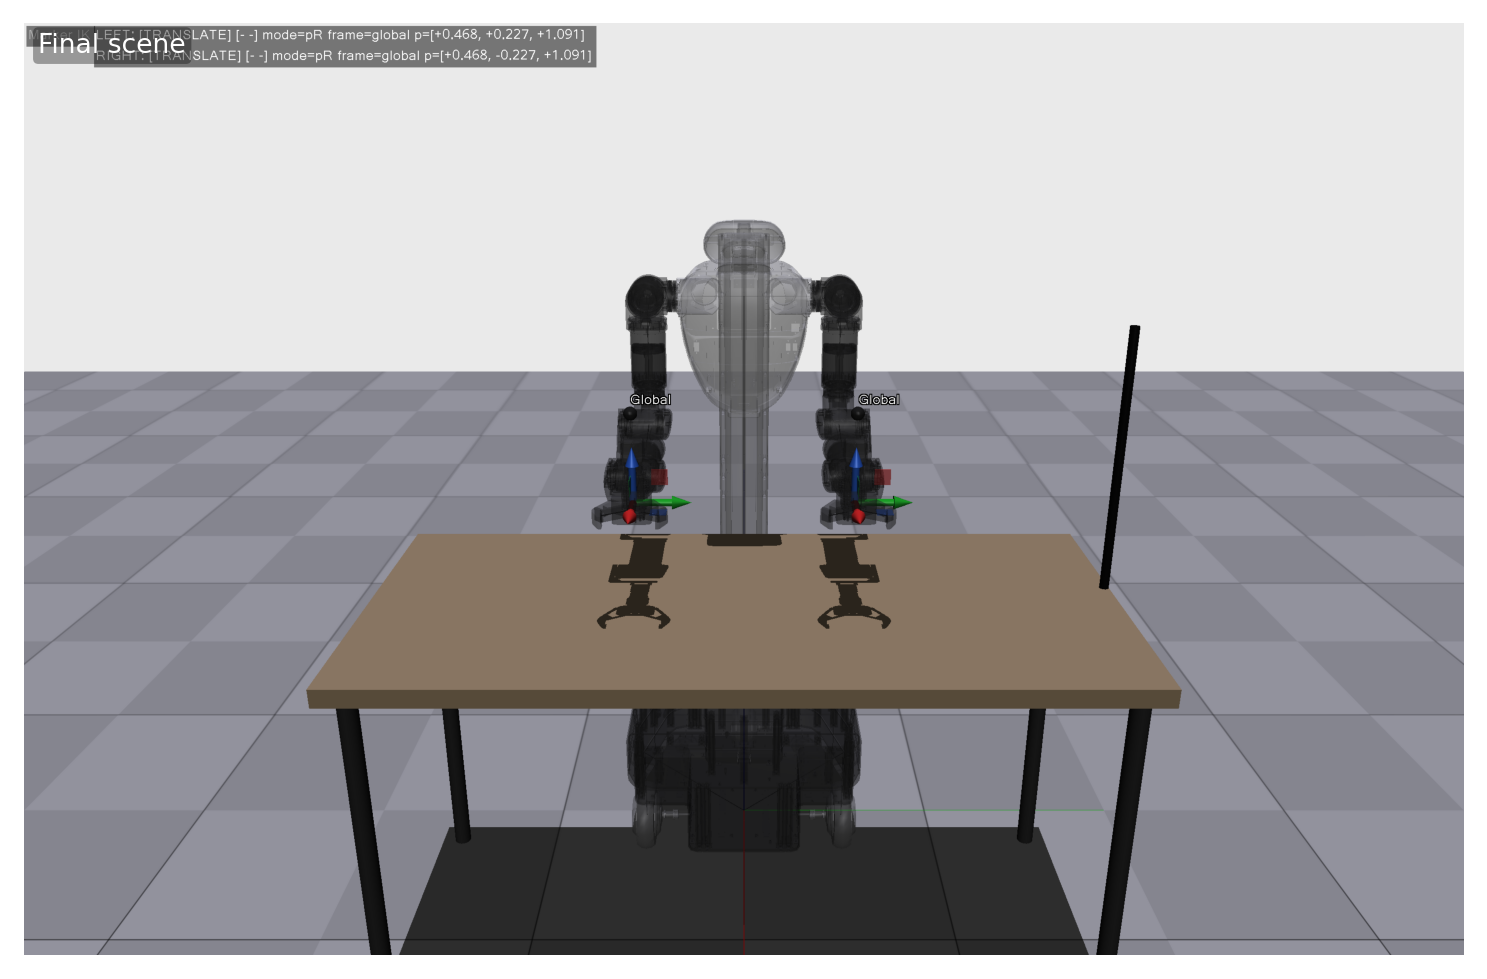

Done.


In [5]:
render_hz = 30
tmr_render = SimpleTimer(name="Marker IK Render",Hz=render_hz,verbose=True)
tmr_render.start(); env.reset_wall_time(); env.reset_sim_time()

try:
    while env.is_viewer_alive():
        app.processEvents()

        if tmr_render.do_run():
            # Poll each gizmo's drag/hover state (no draw yet) so the IK solve below sees the latest drag.
            wrist_targets_by_hand = {
                hand_type: marker.get_T(update=True,draw=False)
                for hand_type,marker in markers.items()
            }

            # Drive each arm toward its own gizmo with an independent small IK solve.
            for hand_type,T_target in wrist_targets_by_hand.items():
                solver = ik_solvers[hand_type]
                solver.reset_buffers(env=env)
                add_sg2_wrist_ik_coordinate_target(
                    ik_solver  = solver,
                    env        = env,
                    hand_type  = hand_type,
                    T_target   = T_target,
                    weight     = 1.0,
                    axis_width = 0.10,)
                _,ik_info = solver.solve_ik(
                    env                     = env,
                    joint_limit_handle_flag = True,
                    nullspace_control_flag  = True,)
                env.forward(q=ik_info["qpos_used_best"],joint_names=solver.joints_use)

            env.plot_global_coordinate_axes()
            env.plot_links_between_bodies(r=0.001)
            for marker in markers.values():
                marker.draw()
            env.viewer_text_overlay(
                "Marker IK",
                "\n".join(
                    "%s: %s"%(hand_type.upper(),marker.get_status())
                    for hand_type,marker in markers.items()
                ),
                loc="top left",)
            env.render()
            tmr_render.end()
except KeyboardInterrupt:
    print("Interrupted.")
finally:
    if getattr(env,"final_rgb_img",None) is not None:
        imshow(env.final_rgb_img,fig_w=6,title="Final scene",title_fs=8)
    env.close_viewer()
    print("Done.")